1- Contou-se o número de erros de impressão da primeira página de um jornal durante 50 dias, obtendo-se os resultados abaixo:

| 1 | 2  | 3 | 4  | 5  | 6  | 7  | 8  | 9  | 10 |
|--:|---:|--:|---:|---:|---:|---:|---:|---:|---:|
| 8 | 11 | 8 | 12 | 14 | 13 | 11 | 14 | 14 | 15 |
| 6 | 10 | 14 | 19 | 6 | 12 | 7 | 5 | 8 | 8 |
| 10 | 16 | 10 | 12 | 12 | 8 | 11 | 6 | 7 | 12 |
| 7 | 10 | 14 | 5 | 12 | 7 | 9 | 12 | 11 | 9 |
| 14 | 8 | 14 | 8 | 12 | 10 | 12 | 22 | 7 | 15 |



 - Calcule as frequências relativas e as frequências relativas acumuladas. Considere a representação individual dos erros e em intervalos de 5 valores
 - Calcule a média, desvio-padrão e assimetria;  
 - Qual a frequência de valores maiores que 10? Qual a frequência de valores menores que 15? Qual a frequência de valores maiores que 10 e menores que 15? 

In [1]:
import pandas as pd

dados = [
    8, 11, 8, 12, 14, 13, 11, 14, 14, 15,
    6, 10, 14, 19, 6, 12, 7, 5, 8, 8, 10,
    16, 10, 12, 12, 8, 11, 6, 7, 12, 7, 10,
    14, 5, 12, 7, 9, 12, 11, 9, 14, 8, 14,
    8, 12, 10, 12, 22, 7, 15
]

serie = pd.Series(dados)

tabela = (
    serie.value_counts()
    .sort_index()
    .rename_axis("xi")
    .reset_index(name="fi")
)

tabela["fri"] = tabela["fi"] / tabela["fi"].sum()
tabela["Fac"] = tabela["fi"].cumsum()
tabela["Fra"] = tabela["fri"].cumsum()

tabela

,xi,fi,fri,Fac,Fra
0,5,2,0.04,2,0.04
1,6,3,0.06,5,0.10
2,7,5,0.10,10,0.20
3,8,7,0.14,17,0.34
4,9,2,0.04,19,0.38
5,10,5,0.10,24,0.48
6,11,4,0.08,28,0.56
7,12,9,0.18,37,0.74
8,13,1,0.02,38,0.76
9,14,7,0.14,45,0.90


Aqui aqui foi atendida a primeira parte do primeiro item. Na segunda parte, devemos separar os dados em intervalos de cinco valores.

In [2]:
classes = [
    "5 a 9",
    "10 a 14",
    "15 a 19",
    "20 a 24"
]

# Somar as frequências fi de cada classe
soma_f1 = tabela["fi"].iloc[0:5].sum()
soma_f2 = tabela["fi"].iloc[5:10].sum()
soma_f3 = tabela["fi"].iloc[10:13].sum()
soma_f4 = tabela["fi"].iloc[13:14].sum()

frequencias_classes = [
    soma_f1,
    soma_f2,
    soma_f3,
    soma_f4
]

tabela_classes = pd.DataFrame({
    "classe": classes,
    "fi": frequencias_classes
})

n = tabela_classes["fi"].sum()

tabela_classes['fri'] = tabela_classes['fi']/tabela_classes['fi'].sum()

tabela_classes['Fra'] = tabela_classes['fri'].cumsum()



tabela_classes


,classe,fi,fri,Fra
0,5 a 9,19,0.38,0.38
1,10 a 14,26,0.52,0.90
2,15 a 19,4,0.08,0.98
3,20 a 24,1,0.02,1.00


2- Quinze barras de concreto fabricadas nas mesmas condições foram submetidas à testes de flexão. Os valores de carga associados à primeira rachadura e ao colapso estão apresentados a seguir: 

## Cargas

| Nº da barra | Carga da 1ª rachadura | Carga de colapso |
|------------:|----------------------:|------------------:|
| 1  | 10350 | 10350 |
| 2  | 8450  | 9300  |
| 3  | 7200  | 9600  |
| 4  | 5100  | 10300 |
| 5  | 6500  | 9400  |
| 6  | 10600 | 10600 |
| 7  | 6000  | 10100 |
| 8  | 6000  | 9900  |
| 9  | 9500  | 9500  |
| 10 | 6500  | 10200 |
| 11 | 9300  | 9300  |
| 12 | 6000  | 9550  |
| 13 | 6000  | 9550  |
| 14 | 5800  | 10500 |
| 15 | 6500  | 10200 |

- Calcule as frequências relativas e as frequências relativas acumuladas de cada tipo de carga. Considere a representação das cargas em intervalos (1000);  
- Calcule a média, desvio-padrão e assimetria para cada tipo de carga;  
- Calcule o coeficiente de correlação.  

In [3]:
import pandas as pd
import numpy as np

numero_barra = list(range(1, 16))

cargas = [
    10350, 8450, 7200, 5100, 6500,
    10600, 6000, 6000, 9500, 6500,
    9300, 6000, 6000, 5800, 6500
]

tabela_2 = pd.DataFrame({
    "Número da Barra (i)": numero_barra,
    "Carga primeira rachadura (xi)": cargas
})

tabela_2 = (
    tabela_2
    .sort_values(by="Carga primeira rachadura (xi)")
    .reset_index(drop=True)
)

tabela_2



,Número da Barra (i),Carga primeira rachadura (xi)
0,4,5100
1,14,5800
2,7,6000
3,8,6000
4,12,6000
5,13,6000
6,10,6500
7,5,6500
8,15,6500
9,3,7200


Dividindo em classes de 1000 na carga teremos:

| Nº da classe | frequência |
|------------:|------------:|
| 1  | 5100 a 6100  | 6 |
| 2  | 6100 a 7100  | 3 |
| 3  | 7100 a 8100  | 1 |
| 4  | 8100 a 9100  | 1 |
| 5  | 9100 a 10100 | 2 |
| 6  | 10100 a 10600| 2 |

ou ainda pode-fazer pela fórmula de Sturges, onde:

$$k=1+3,332\cdot \log(N)$$

onde $N$ é o número de observações. Então:

o valor mínimo é 5100 e;
o valor máximo é 10600.

In [4]:
N = 15
k = 1 + 3.332*np.log10(N)
k = 5
print(f'O número de classes é: {k}')


O número de classes é: 5


In [5]:
maximo = 10600
minimo = 5100

amplitude = maximo - minimo
amplitude_classe = amplitude / 5
print(f'A Amplitude é igual: {amplitude}')
print(f'A Amplitude da classe é igual: {amplitude_classe}')


A Amplitude é igual: 5500
A Amplitude da classe é igual: 1100.0


In [6]:
classes_carga = [
                "5100 a 6200",
                "6200 a 7300",
                "7300 a 8400",
                "8400 a 9500",
                "9500 a 10600"
                ]

carga = tabela_2["Carga primeira rachadura (xi)"]

soma_f1 = carga[
    (carga >= 5100) & (carga < 6200)
].count()

soma_f2 = carga[
    (carga >= 6200) & (carga < 7300)
].count()

soma_f3 = carga[
    (carga >= 7300) & (carga < 8400)
].count()

soma_f4 = carga[
    (carga >= 8400) & (carga < 9500)
].count()

soma_f5 = carga[
    (carga >= 9500) & (carga <= 10600)
].count()


frequencias_classes = [
    soma_f1,
    soma_f2,
    soma_f3,
    soma_f4,
    soma_f5
]

dados_carga = pd.DataFrame({
    "Classes de Carga": classes_carga,
    "fi": frequencias_classes
})

n = dados_carga["fi"].sum()

dados_carga['fri'] = dados_carga['fi'] / n

dados_carga['Fra'] = dados_carga['fri'].cumsum()

centro_classe = {'Centro da Classe': [(5100+6200)/2, (6200+7300)/2, (7300+8400)/2, (8400+9500)/2, (9500+10600)/2]}

dados_carga['Centro da Classe'] = centro_classe['Centro da Classe']


media = (
    dados_carga['fri'] *
    dados_carga['Centro da Classe']
).sum()

var = (
    dados_carga['fri'] *
    (dados_carga['Centro da Classe'] - media)**2
).sum()

std = np.sqrt(var)

print(f'Média agrupada: {media:.2f}')
print(f'Variância agrupada: {var:.2f}')
print(f'Desvio padrão agrupado: {std:.2f}')

Média agrupada: 7263.33
Variância agrupada: 3043822.22
Desvio padrão agrupado: 1744.66


In [7]:
dados_carga

,Classes de Carga,fi,fri,Fra,Centro da Classe
0,5100 a 6200,6,0.400000,0.400000,5650.0
1,6200 a 7300,4,0.266667,0.666667,6750.0
2,7300 a 8400,0,0.000000,0.666667,7850.0
3,8400 a 9500,2,0.133333,0.800000,8950.0
4,9500 a 10600,3,0.200000,1.000000,10050.0


## As cargas de colapso são:

| Nº da barra| Carga de colapso |
|-----------:|------------------:|
| 1  | 10350 |
| 2  | 9300  |
| 3  | 9600  |
| 4  | 10300 |
| 5  | 9400  |
| 6  | 10600 |
| 7  | 10100 |
| 8  | 9900  |
| 9  | 9500  |
| 10 | 10200 |
| 11 | 9300  |
| 12 | 9550  |
| 13 | 9550  |
| 14 | 10500 |
| 15 | 10200 |



In [8]:
cargas_colapso = [10350, 9300, 9600, 10300, 9400,
                  10600, 10100, 9900, 9500, 10200,
                  9300, 9550, 9550, 10500, 10200]

tabela_3 = pd.DataFrame({
    "Número da Barra (i)": numero_barra,
    "Carga de Colapso (xi)": cargas_colapso
})

tabela_3 = (
    tabela_3
    .sort_values(by="Carga de Colapso (xi)")
    .reset_index(drop=True)
)

tabela_3

,Número da Barra (i),Carga de Colapso (xi)
0,2,9300
1,11,9300
2,5,9400
3,9,9500
4,13,9550
5,12,9550
6,3,9600
7,8,9900
8,7,10100
9,10,10200


Sendo o número de observações o mesmo do item anterior, usaremos 5 classes.  
então as classes seriam dadas por:

In [9]:
max_colapso = tabela_3['Carga de Colapso (xi)'].max()
min_colapso = tabela_3['Carga de Colapso (xi)'].min()
amplitude_colapso = max_colapso - min_colapso
print(f'A amplitude_colapso é: {amplitude_colapso:.2f}')

A amplitude_colapso é: 1300.00


In [10]:
classes_carga_colapso = [
    "9300 a 9560",
    "9560 a 9820",
    "9820 a 10080",
    "10080 a 10340",
    "10340 a 10600"
]

carga_colapso = tabela_3["Carga de Colapso (xi)"]

soma_f1 = carga_colapso[
    (carga_colapso >= 9300) & (carga_colapso < 9560)
].count()

soma_f2 = carga_colapso[
    (carga_colapso >= 9560) & (carga_colapso < 9820)
].count()

soma_f3 = carga_colapso[
    (carga_colapso >= 9820) & (carga_colapso < 10080)
].count()

soma_f4 = carga_colapso[
    (carga_colapso >= 10080) & (carga_colapso < 10340)
].count()

soma_f5 = carga_colapso[
    (carga_colapso >= 10340) & (carga_colapso <= 10600)
].count()

frequencias_classes = [
    soma_f1,
    soma_f2,
    soma_f3,
    soma_f4,
    soma_f5
]

print("Frequências:", frequencias_classes)
print("Total contado:", n)
print("Total original:", len(carga_colapso))

# Nome da tabela
dados_carga_colapso = pd.DataFrame({
    "Classes de Carga": classes_carga_colapso,
    "fi": frequencias_classes
})

# Total de observações desta tabela
n = dados_carga_colapso["fi"].sum()

# Centros das classes
centro_classe_colapso = [
    (9300 + 9560) / 2,
    (9560 + 9820) / 2,
    (9820 + 10080) / 2,
    (10080 + 10340) / 2,
    (10340 + 10600) / 2
]

# Frequência relativa
dados_carga_colapso["fri"] = (
    dados_carga_colapso["fi"] / n
)

# Frequência relativa acumulada
dados_carga_colapso["Fra"] = (
    dados_carga_colapso["fri"].cumsum()
)

# Centro das classes
dados_carga_colapso["Centro da Classe"] = (
    centro_classe_colapso
)

dados_carga_colapso


Frequências: [np.int64(6), np.int64(1), np.int64(1), np.int64(4), np.int64(3)]
Total contado: 15
Total original: 15


,Classes de Carga,fi,fri,Fra,Centro da Classe
0,9300 a 9560,6,0.400000,0.400000,9430.0
1,9560 a 9820,1,0.066667,0.466667,9690.0
2,9820 a 10080,1,0.066667,0.533333,9950.0
3,10080 a 10340,4,0.266667,0.800000,10210.0
4,10340 a 10600,3,0.200000,1.000000,10470.0


### Calcular a média, VAR e std.

In [11]:
media_colapso = (dados_carga_colapso['fri'] * dados_carga_colapso['Centro da Classe']).sum()
var_colapso = (((dados_carga_colapso['Centro da Classe']-media_colapso)**2) * dados_carga_colapso['fri']).sum()
std_colapso = np.sqrt(var_colapso)
print(media_colapso)
print(var_colapso)
print(std_colapso)

9898.0
182069.3333333333
426.6958323364939


3– Sejam os dados de tempos de reação a um estímulo (Y) e acuidade visual (Z) de 20 indivíduos.  

| Indivíduo |  Y  |  Z  |
|----------:|----:|----:|
| 1  | 96  | 90  |
| 2  | 92  | 100 |
| 3  | 106 | 80  |
| 4  | 100 | 90  |
| 5  | 98  | 100 |
| 6  | 104 | 90  |
| 7  | 110 | 80  |
| 8  | 101 | 90  |
| 9  | 116 | 70  |
| 10 | 106 | 90  |
| 11 | 109 | 90  |
| 12 | 100 | 80  |
| 13 | 112 | 90  |
| 14 | 105 | 80  |
| 15 | 118 | 70  |
| 16 | 108 | 90  |
| 17 | 113 | 90  |
| 18 | 112 | 90  |
| 19 | 127 | 60  |
| 20 | 117 | 80  |


- Calcule a distribuição de frequências das duas variáveis aleatórias (considere a representação individual ou por classe).
- Calcule a distribuição de frequências conjunta das duas variáveis aleatórias (considere a representação individual).  
- Calcule o coeficiente de variação de cada uma das duas variáveis aleatórias e interprete-os.  
- Qual a frequência de tempo de reação a um estímulo maior que 100? Qual a frequência de tempo de reação a um estímulo menor que 120? Qual a frequência de tempo de reação a um estímulo maior que 100 e menor que 120?  
- Calcule os quartis das duas distribuições de frequências. Monte o diagrama de Box-Plot.  
- Calcule o coeficiente de correlação entre os tempos de reação a um estímulo e a acuidade visual desse conjunto de indivíduos. Interprete-o. 

### Para a variável y

In [12]:
# distribuição de frequências
import matplotlib.pyplot as plt
n = 20
individuo = list(range(1, 21))

y = [96, 92, 106, 100, 98, 104, 110, 101, 116, 106, 109, 100, 112, 105, 118, 108, 113, 112, 127, 117]
z = [90, 100, 80, 90, 100, 90, 80, 90, 70, 100, 90, 80, 90, 80, 70, 90, 90, 90, 60, 80]
df = pd.DataFrame({
    "indivíduo": individuo,
    "y": y,
    "z": z
})
freq_y = (
    df["y"]
    .value_counts()
    .sort_index()
    .reset_index()
)

freq_y.columns = ["Y", "fi_y"]
freq_y['Fi_y'] = freq_y['fi_y'].cumsum()
freq_y['fr_y'] = freq_y["fi_y"] / n
freq_y['Frac'] = freq_y["fr_y"].cumsum()
freq_y

,Y,fi_y,Fi_y,fr_y,Frac
0,92,1,1,0.05,0.05
1,96,1,2,0.05,0.10
2,98,1,3,0.05,0.15
3,100,2,5,0.10,0.25
4,101,1,6,0.05,0.30
5,104,1,7,0.05,0.35
6,105,1,8,0.05,0.40
7,106,2,10,0.10,0.50
8,108,1,11,0.05,0.55
9,109,1,12,0.05,0.60


In [13]:
# Valor da média
media_y = (freq_y['Y'] * freq_y['fr_y']).sum()
print(f'A media da variável Y é: {media_y:.2f}')

var_y = (freq_y['fi_y']*((freq_y['Y']-media_y)**2)/n).sum()
print(f'A variância de Y é: {var_y:.2f}')

std_y = np.sqrt(var_y)
print(f'O desvio padrão de Y é: {std_y:.2f}')

cv_y = std_y / media_y
print(f'o Coeficiente de Y é: {cv_y:.2f}')

A media da variável Y é: 107.50
A variância de Y é: 68.65
O desvio padrão de Y é: 8.29
o Coeficiente de Y é: 0.08


### Para a variável z

In [14]:
freq_z = (
    df["z"]
    .value_counts()
    .sort_index()
    .reset_index()
)

freq_z.columns = ["Z", "fi_z"]

freq_z['Fi_z'] = freq_z['fi_z'].cumsum()
freq_z['fr_z'] = freq_z['fi_z'] / n
freq_z['Frac_z'] = freq_z['fr_z'].cumsum()

freq_z

,Z,fi_z,Fi_z,fr_z,Frac_z
0,60,1,1,0.05,0.05
1,70,2,3,0.10,0.15
2,80,5,8,0.25,0.40
3,90,9,17,0.45,0.85
4,100,3,20,0.15,1.00


In [15]:
# Valor da média
media_z = (freq_z['Z'] * freq_z['fr_z']).sum()
print(f'A media da variável Z é: {media_z:.2f}')

var_z = ((freq_z['fi_z']*(freq_z['Z']-media_z)**2)/n).sum()
print(f'A variância de Z é: {var_z:.2f}')

std_z = np.sqrt(var_z)
print(f'O desvio padrão de Z é: {std_z:.2f}')

cv_z = std_z / media_z
print(f'o Coeficiente de Z é: {cv_z:.2f}')

A media da variável Z é: 85.50
A variância de Z é: 104.75
O desvio padrão de Z é: 10.23
o Coeficiente de Z é: 0.12


## Quantis de Y e Z

In [16]:
y_ord = np.array(sorted(y))
md = (y_ord[9]+y_ord[10])/2
print(y_ord)
print(f'A mediana é: {md:.2f}')
q1 = y_ord[4]
print(f'o valor de Q1 é: {q1:.2f}')
q3 = (y_ord[14])
print(f'o valor de Q3 é: {q3:.2f}')

[ 92  96  98 100 100 101 104 105 106 106 108 109 110 112 112 113 116 117
 118 127]
A mediana é: 107.00
o valor de Q1 é: 100.00
o valor de Q3 é: 112.00


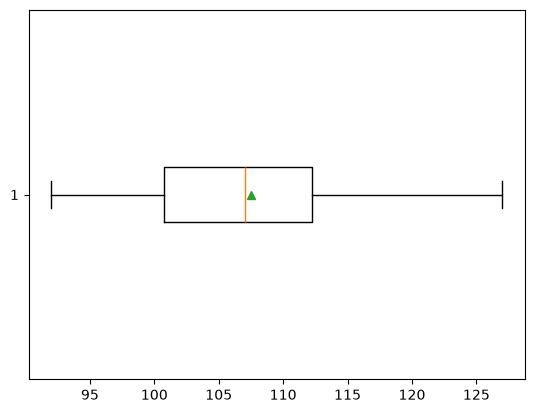

In [17]:
plt.boxplot(y_ord, orientation='horizontal', showmeans=True);
plt.show()

In [18]:
z_ord = np.array(sorted(z))
md = (z_ord[9]+z_ord[10])/2
print(z_ord)
print(f'A mediana é: {md:.2f}')
q1 = y_ord[4]
print(f'o valor de Q1 é: {q1:.2f}')
q3 = (y_ord[14])
print(f'o valor de Q3 é: {q3:.2f}')

[ 60  70  70  80  80  80  80  80  90  90  90  90  90  90  90  90  90 100
 100 100]
A mediana é: 90.00
o valor de Q1 é: 100.00
o valor de Q3 é: 112.00


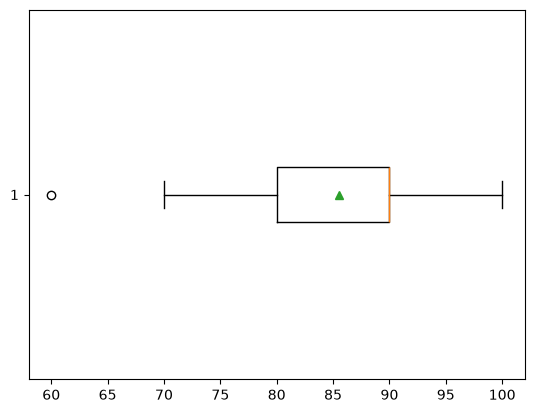

In [19]:
plt.boxplot(z_ord, orientation='horizontal', showmeans=True);
plt.show()

4 – Após um tratamento, seis operários submeteram-se a um teste e, mais tarde, mediu-se a produtividade de cada um deles. A partir dos resultados apresentados na tabela abaixo, calcule o coeficiente de correlação entre a nota do teste e a produtividade. O que podemos aferir desse resultado? Calcule também a assimetria da amostra teste e da amostra produtividade e compare-as.

| Operário | 1 | 2  | 3  | 4  | 5  | 6  |
|---------:|--:|---:|---:|---:|---:|---:|
| Teste | 9 | 17 | 20 | 19 | 20 | 23 |
| Produtividade | 22 | 34 | 29 | 33 | 42 | 32 |

5– Procurando quantificar os efeitos da escassez de sono sobre a capacidade de resolução de problemas simples, um agente tomou ao acaso 10 sujeitos e os submeteu a experimentação. Deixou-os sem dormir por diferentes números de horas, após o que solicitou que os mesmos resolvessem os itens "contas de adicionar" de um teste. Obteve, assim, os seguintes dados: 

| Nº de erros — Y | Horas sem dormir — X |
|----------------:|----------------------:|
| 8  | 8  |
| 6  | 8  |
| 6  | 12 |
| 10 | 12 |
| 8  | 16 |
| 14 | 16 |
| 14 | 20 |
| 12 | 20 |
| 16 | 24 |
| 12 | 24 |

Calcule o coeficiente de correlação. Pode-se concluir que horas sem dormir afeta a capacidade de um sujeito durante um teste? 

6 – Em um exame de colesterol, o grau médio de um grupo “A” de 150 pessoas foi de 214 mg/dl e um desvio-padrão de 22 mg/dl. Em outro grupo “B”, entretanto, o grau médio em 150 pessoas foi de 201 mg/dl e um desvio-padrão de 21 mg/dl. Em que grupo foi maior a dispersão? 

| Renda familiar (X) | Gasto com alimentação (Y) |
|-------------------:|--------------------------:|
| 3   | 1,5  |
| 5   | 2,0  |
| 10  | 6,0  |
| 10  | 7,0  |
| 20  | 10,0 |
| 20  | 12,0 |
| 20  | 15,0 |
| 30  | 8,0  |
| 40  | 10,0 |
| 50  | 20,0 |
| 60  | 20,0 |
| 70  | 25,0 |
| 70  | 30,0 |
| 80  | 25,0 |
| 100 | 40,0 |
| 100 | 35,0 |
| 100 | 40,0 |
| 120 | 30,0 |
| 120 | 40,0 |
| 140 | 40,0 |
| 150 | 50,0 |
| 180 | 40,0 |
| 180 | 50,0 |
| 200 | 60,0 |
| 200 | 50,0 |


- Calcule a distribuição de frequências das duas variáveis aleatórias.  
- ~~Calcule a distribuição de frequências conjunta das duas variáveis aleatórias.~~  
- Calcule o coeficiente de variação de cada uma das duas variáveis aleatórias e interprete-os. 
- Calcule o coeficiente de correlação entre a renda familiar e o gasto com alimentação desse conjunto de indivíduos. Interprete-o. 
- Calcule os quartis das duas distribuições de frequências. Monte o diagrama de Box-Plot. 

7 - renda familiar e gastos com alimentação.

In [20]:
renda_familiar = [
    3, 5, 10, 10, 20, 20,
    20, 30, 40, 50, 60, 70,
    70, 80, 100, 100, 100,
    120, 120, 140, 150, 180,
    180, 200, 200
]
n_renda = len(renda_familiar)
renda_familiar = pd.DataFrame({
    'Renda Familiar': renda_familiar
})

freq_renda = (
    renda_familiar["Renda Familiar"]
    .value_counts()
    .sort_index()
    .reset_index()
)

freq_renda.columns = ["Renda", "fi_renda"]

freq_renda["Fi_renda"] = freq_renda["fi_renda"].cumsum()
freq_renda["fr_renda"] = freq_renda["fi_renda"] / n_renda
freq_renda["Fr_renda"] = freq_renda["fr_renda"].cumsum()


freq_renda


,Renda,fi_renda,Fi_renda,fr_renda,Fr_renda
0,3,1,1,0.04,0.04
1,5,1,2,0.04,0.08
2,10,2,4,0.08,0.16
3,20,3,7,0.12,0.28
4,30,1,8,0.04,0.32
5,40,1,9,0.04,0.36
6,50,1,10,0.04,0.40
7,60,1,11,0.04,0.44
8,70,2,13,0.08,0.52
9,80,1,14,0.04,0.56


### Estatísticas.

a média é:

$$ \bar{x} = \sum(fr_i \cdot x_i) $$

a variância é:
$$ \sigma^2 = \frac{\sum (x_1 - \bar{x})^2}{n} $$

e o desvio padrão:

$$\sigma = \sqrt{\sigma^2} $$

e a assimetria: 

$$g=\frac{{\sum (x_1 - \bar{x})^3}}{n\cdot \sigma^3}$$

In [21]:
# média

media_renda = (
    freq_renda['Renda'] * freq_renda['fr_renda']
).sum()

var_renda = (
    freq_renda['fi_renda']
    * (freq_renda['Renda'] - media_renda)**2
).sum() / n

std_renda = np.sqrt(var_renda)

cv_renda = std_renda / media_renda * 100

g_renda = (((freq_renda['Renda'] - media_renda)**3).sum()) / (n * (std_renda)**3)




print(f'O valor da media da renda é: {media_renda}')
print(f'O valor da variância da renda é: {var_renda:.2f}')
print(f'O valor do desvio padrão da renda é: {std_renda:.2f}')
print(f'O valor do coeficiente de variação é: {cv_renda:.2f}%')
print(f'O valor da assimetria é: {g_renda:.2f}')

# resultados

O valor da media da renda é: 83.12
O valor da variância da renda é: 4960.53
O valor do desvio padrão da renda é: 70.43
O valor do coeficiente de variação é: 84.73%
O valor da assimetria é: 0.16


*O coeficiente de variação (CV) mede a dispersão dos dados em relação à média. Um CV baixo indica alta homogeneidade e estabilidade, enquanto um CV alto aponta grande dispersão e instabilidade. O valor padrão geral classifica variações até 10% como baixas, e acima de 30% como muito altas.*

## Quantis da renda familiar.

In [22]:
renda_familiar = [
    3, 5, 10, 10, 20, 20,
    20, 30, 40, 50, 60, 70,
    70, 80, 100, 100, 100,
    120, 120, 140, 150, 180,
    180, 200, 200
]

n_renda = len(renda_familiar)

dados_renda = pd.DataFrame({
    "Renda Familiar": renda_familiar
})



Para o gráfico eu vou usar o recurso do Python.

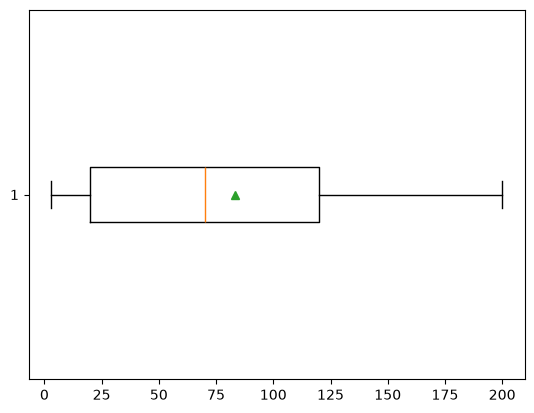

In [23]:
plt.boxplot(renda_familiar, orientation='horizontal', showmeans=True);
plt.show()

## Variável Y custos da alimentação

In [24]:
aliment = [
    1.5, 2, 6, 7, 10, 12,
    15, 8, 10, 20, 20, 25,
    30, 25, 40, 35, 40,
    30, 40, 40, 50, 40,
    50, 60, 50
]

n = len(aliment)

dados_aliment = pd.DataFrame({
    'Gastos com Alimentação': aliment
})

freq_aliment = (
    dados_aliment['Gastos com Alimentação']
    .value_counts()
    .sort_index()
    .reset_index()
)

freq_aliment.columns = ["Gastos com Alimentação", "fi_aliment"]

freq_aliment["Fi_aliment"] = freq_aliment["fi_aliment"].cumsum()
freq_aliment["fr_aliment"] = freq_aliment["fi_aliment"] / n
freq_aliment["Fr_aliment"] = freq_aliment["fr_aliment"].cumsum()

freq_aliment


,Gastos com Alimentação,fi_aliment,Fi_aliment,fr_aliment,Fr_aliment
0,1.5,1,1,0.04,0.04
1,2.0,1,2,0.04,0.08
2,6.0,1,3,0.04,0.12
3,7.0,1,4,0.04,0.16
4,8.0,1,5,0.04,0.20
5,10.0,2,7,0.08,0.28
6,12.0,1,8,0.04,0.32
7,15.0,1,9,0.04,0.36
8,20.0,2,11,0.08,0.44
9,25.0,2,13,0.08,0.52


In [25]:
media_aliment = (
    freq_aliment['Gastos com Alimentação'] * freq_aliment['fr_aliment']
).sum()

var_aliment = (
    freq_aliment['fi_aliment']
    * (freq_aliment['Gastos com Alimentação'] - media_aliment)**2
).sum() / n

std_aliment = np.sqrt(var_aliment)

cv_aliment = std_aliment / media_aliment * 100

g_renda = (((freq_aliment['Gastos com Alimentação'] - media_aliment)**3).sum()) / (n * (std_aliment)**3)



print(f'O valor da media dos gastos com alimentação é: {media_aliment:.2f}')
print(f'O valor do custo de alimentação é: {var_aliment:.2f}')
print(f'O valor do desvio padrão da renda é: {std_aliment:.2f}')
print(f'O valor do coeficiente de variação é: {cv_renda:.2f}%')
print(f'O valor da assimetria é: {g_renda:.2f}')

O valor da media dos gastos com alimentação é: 26.66
O valor do custo de alimentação é: 285.21
O valor do desvio padrão da renda é: 16.89
O valor do coeficiente de variação é: 84.73%
O valor da assimetria é: -0.09


### Quantis dos gastos com Alimentação.

In [26]:
gastos_aliment = [
    1.5, 2, 6, 7, 10, 12,
    15, 8, 10, 20, 20, 25,
    30, 25, 40, 35, 40,
    30, 40, 40, 50, 40,
    50, 60, 50
]

n_gastos = len(gastos_aliment)

dados_gastos = pd.DataFrame({
    "Gastos com Alimentação": gastos_aliment
})

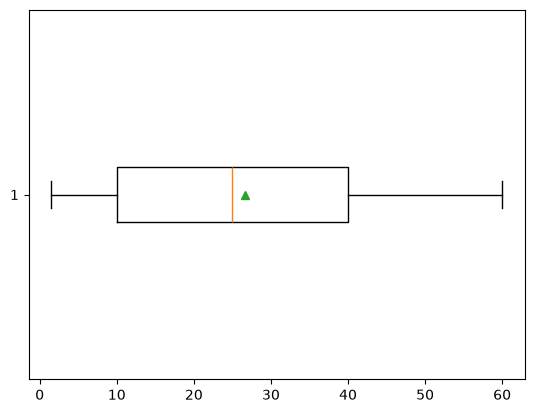

In [27]:
plt.boxplot(dados_aliment, orientation='horizontal', showmeans=True);
plt.show()

8- Os valores da precipitação (em mm) registrada em uma Estação Meteorológica, nos 31 dias de janeiro de 2014, estão listados na tabela:

| Dia | Precipitação |
|----:|-------------:|
| 1  | 0.0  |
| 2  | 0.0  |
| 3  | 0.0  |
| 4  | 0.0  |
| 5  | 4.7  |
| 6  | 0.6  |
| 7  | 17.2 |
| 8  | 1.4  |
| 9  | 11.2 |
| 10 | 1.0  |
| 11 | 3.8  |
| 12 | 0.3  |
| 13 | 0.0  |
| 14 | 0.0  |
| 15 | 0.5  |
| 16 | 7.0  |
| 17 | 0.0  |
| 18 | 0.0  |
| 19 | 3.3  |
| 20 | 7.6  |
| 21 | 0.9  |
| 22 | 0.3  |
| 23 | 18.2 |
| 24 | 4.0  |
| 25 | 4.6  |
| 26 | 22.0 |
| 27 | 15.6 |
| 28 | 0.0  |
| 29 | 3.4  |
| 30 | 0.0  |
| 31 | 0.0  |

- Escolha a melhor forma de representar os dados: representação individual ou por classes. Justifique. 
- Apresente a distribuição de frequências relativa e a distribuição de frequências relativa acumulada. 
- Apresente estatísticas de valores centrais. 
- Apresente estatísticas de dispersão. 
- Apresente estatísticas de forma. - Apresente o boxplot (gráfico de caixa) da variável aleatória. 
- Calcule os valores da variável aleatória correspondentes ao 1º, 2º e 3º quartis. 

In [28]:
dia = list(range(1, 32))

precipita = [0.0, 0.0, 0.0, 0.0, 4.7, 0.6, 17.2, 1.4, 11.2,
             1.0, 3.8, 0.3, 0.0, 0.0, 0.5, 7, 0.0, 0.0, 3.3, 7.6, 0.9,
             0.3, 18.2, 4, 4.6, 22, 15.6, 0, 3.4, 0.0, 0.0]
n_precipita = len(precipita)

dados_precipita = pd.DataFrame({
    "Dia": dia, "Precipitação": precipita
})


freq_precipita = (
    dados_precipita["Precipitação"]
    .value_counts()
    .sort_index()
    .reset_index()
)

freq_precipita.columns = ["Precipitação", "fi_precipita"]

freq_precipita["Fi_precipita"] = freq_precipita["fi_precipita"].cumsum()
freq_precipita["fr_precipita"] = freq_precipita["fi_precipita"] / n_precipita
freq_precipita["Fr_precipita"] = freq_precipita["fr_precipita"].cumsum()


In [29]:
# Média
media_precipita = (freq_precipita['fr_precipita'] * freq_precipita['Precipitação']).sum()
var_precipita = (((freq_precipita["Precipitação"] - media_precipita)**2).sum()) /n_precipita
moda_precipita = 0.0

precipita_ord = sorted(precipita)

print(f'A média da Precipitação é: {media_precipita:.2f}')
print(f'A média da Precipitação é: {var_precipita:.2f}')
#print(f'A moda da Precipitação é: {moda_precipita}')

mediana_precipita = precipita_ord[30]


A média da Precipitação é: 4.12
A média da Precipitação é: 31.55
